# Exploratory Data Analysis — DAD Data-Center IoT Sensor Network

**Dataset:** DAD (Vigoya et al., 2020) — 7 days of MQTT sensor traffic from a data-center cooling
system, captured as network packets, with **real, human-labelled attacks** (duplication, interception,
modification of MQTT messages). This notebook is a standard end-to-end EDA: dataset overview and quality,
temperature distributions, **trend and seasonality (STL)**, autocorrelation, sensor correlations,
network-traffic patterns, the labelled attacks, the two detector channels, and the detection results.

**How to run:** `bash tools/get_dad_dataset.sh` to fetch the data, then *Restart & Run All*.

## Contents
1. Setup & load  2. Dataset overview & data dictionary  3. Data quality  4. The sensors
5. Temperature distribution  6. Time series  7. **Trend & seasonality (STL)**  8. Autocorrelation
9. Sensor correlations  10. Network traffic  11. The attacks  12. The two detector channels
13. Detection results  14. Ask in plain English  15. Conclusions


## 1. Setup & load
We parse the 7 packet captures into one datetime-indexed **MESSAGES** frame — the single source of truth (one row per packet; temperature parsed from the MQTT payload; attack label joined from the label CSVs).

In [1]:
import sys, pathlib, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, str(pathlib.Path.cwd().parent))
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src import preprocess, features, channels, experiment
from src import query_engine as qe, interface
plt.rcParams["figure.figsize"] = (9, 3.2); plt.rcParams["axes.grid"] = True

df = preprocess.load_week()
print("MESSAGES frame:", df.shape, "(packets x columns)")
df.head()

MESSAGES frame: (101583, 10) (packets x columns)


,frame,src_ip,src_port,topic,temperature,clientid,msgid,label,day,attack_type
ts,,,,,,,,,,
2019-10-20 22:00:02.449276924,1,10.6.56.36,47590.0,NaN,NaN,NaN,NaN,0,mon,none
2019-10-20 22:00:02.449343920,2,10.6.56.1,1883.0,NaN,NaN,NaN,NaN,0,mon,none
2019-10-20 22:00:02.449383974,3,10.6.56.36,47588.0,NaN,NaN,NaN,NaN,0,mon,none
2019-10-20 22:00:02.449403048,4,10.6.56.1,1883.0,NaN,NaN,NaN,NaN,0,mon,none
2019-10-20 22:00:02.449471951,5,10.6.56.36,47592.0,NaN,NaN,NaN,NaN,0,mon,none


## 2. Dataset overview & data dictionary

| column | meaning |
|---|---|
| `ts` (index) | packet timestamp (UTC) |
| `frame` | packet number in the capture (join key to the labels) |
| `src_ip` | source IP (`10.6.56.41` is the attacker) |
| `src_port` | TCP source port |
| `topic` | MQTT topic (all sensors publish to `IoT`) |
| `temperature` | reading parsed from the MQTT PUBLISH payload (`NaN` if not a publish) |
| `clientid` | MQTT client = sensor id (e.g. `131` = InRow-13 probe 1) |
| `msgid` | MQTT message/token id |
| `label` | **ground truth**: 0 normal / 1 attack |
| `attack_type` | modification / duplication / mixed / none (day-level) |


In [2]:
df.dtypes

frame            int64
src_ip             str
src_port       float64
topic              str
temperature    float64
clientid       float64
msgid          float64
label             int8
day                str
attack_type        str
dtype: object

In [3]:
df["temperature"].describe().round(2)

count    32288.00
mean        18.43
std          5.76
min          8.67
25%         13.22
50%         17.45
75%         22.62
max         29.40
Name: temperature, dtype: float64

## 3. Data quality
How complete is the capture, and what is the class balance?

In [4]:
print(f"packets ............ {len(df):,}")
print(f"temperature readings  {int(df.temperature.notna().sum()):,}  (MQTT PUBLISH messages)")
print(f"labelled attacks ...  {int(df.label.sum())}  ({df.label.mean()*100:.2f}% of packets)")
print(f"distinct source IPs   {df.src_ip.nunique()}")
print(f"time span ..........  {df.index.min()}  ->  {df.index.max()}")
print(f"missing temperature on publishes: {int(df.loc[df.topic=='IoT','temperature'].isna().sum())}")

packets ............ 101,583
temperature readings  32,288  (MQTT PUBLISH messages)
labelled attacks ...  544  (0.54% of packets)
distinct source IPs   5
time span ..........  2019-10-20 22:00:02.449276924  ->  2019-10-27 21:55:31.656127930
missing temperature on publishes: 0


## 4. The sensors
Sixteen simulated probes: four **InRow** cooling units (13, 15, 23, 25), each with four sensors
(supply-air, return-air, entering-fluid, leaving-fluid). The client id encodes unit + probe, so
`131` = InRow **13**, probe **1**.

In [5]:
ids = sorted(int(c) for c in df.clientid.dropna().unique())
print("sensor client ids:", ids)
print("count:", len(ids), "(4 InRow units x 4 probes)")

sensor client ids: [131, 132, 133, 134, 151, 152, 153, 154, 231, 232, 233, 234, 251, 252, 253, 254]
count: 16 (4 InRow units x 4 probes)


## 5. Temperature distribution
The spread of all reported readings (data-center cooling temperatures).

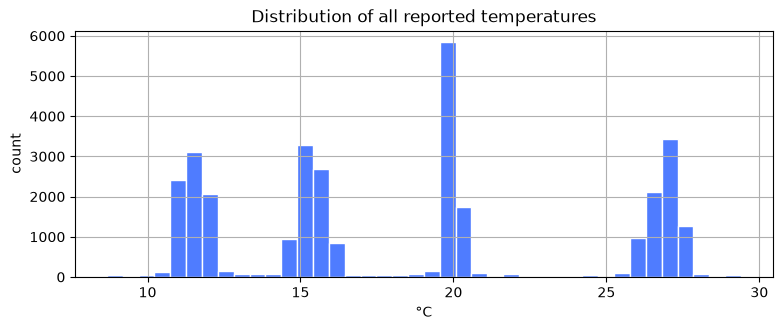

In [6]:
temps = df.temperature.dropna()
plt.hist(temps, bins=40, color="#4f7cff", edgecolor="white")
plt.title("Distribution of all reported temperatures"); plt.xlabel("°C"); plt.ylabel("count"); plt.show()

## 6. Time series
Temperature over the week for a few sensors, resampled to the native 5-minute grid.

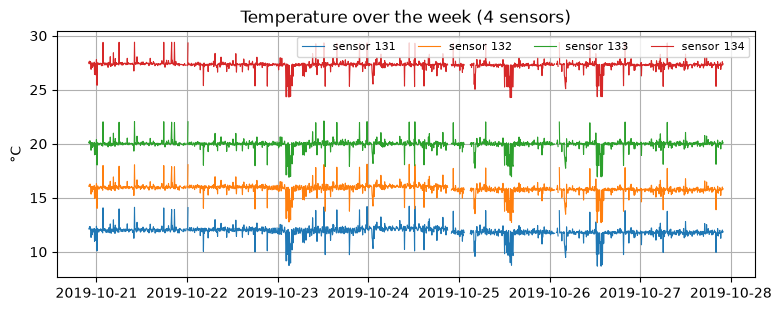

In [7]:
sensors = features.sensor_series(df, "5min")
for c in list(sensors.columns)[:4]:
    plt.plot(sensors.index, sensors[c], lw=0.8, label=f"sensor {int(c)}")
plt.legend(ncol=4, fontsize=8); plt.title("Temperature over the week (4 sensors)"); plt.ylabel("°C"); plt.show()

## 7. Trend & seasonality — STL decomposition
Real sensor series combine a slow **trend**, a repeating **seasonal** cycle, and a **residual**
(noise + anomalies). **STL** (Seasonal-Trend decomposition using Loess) separates them. We use a daily
period (288 five-minute windows per day). *Note:* DAD's normal traffic was itself generated from an STL
model, so a clean daily season is expected — which is exactly why residual spikes flag modification
attacks.

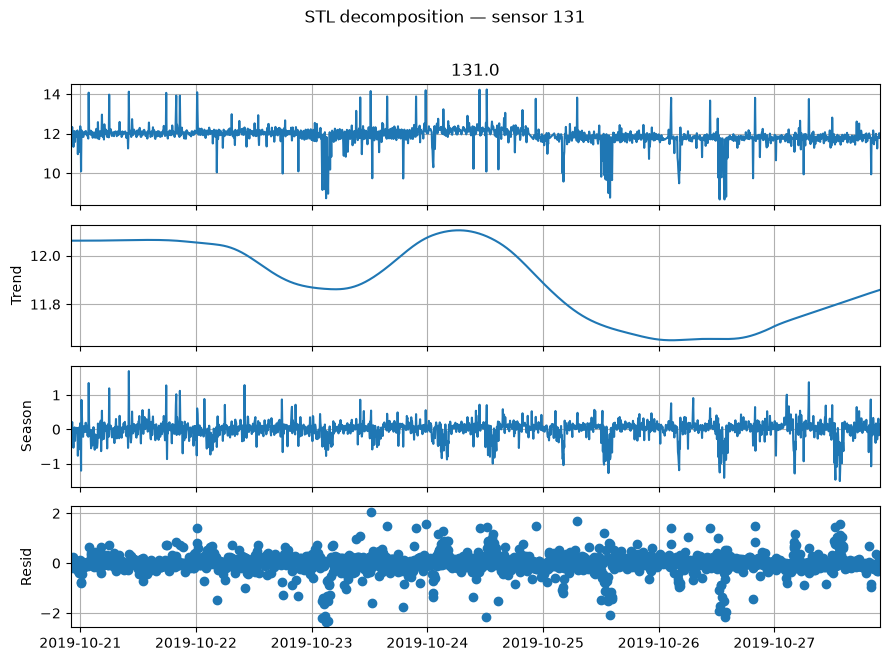

In [8]:
from statsmodels.tsa.seasonal import STL
s1 = sensors.iloc[:, 0].interpolate().ffill().bfill()
res = STL(s1, period=288).fit()
fig = res.plot(); fig.set_size_inches(9, 6.5)
plt.suptitle(f"STL decomposition — sensor {int(sensors.columns[0])}", y=1.01); plt.tight_layout(); plt.show()

## 8. Autocorrelation
The ACF confirms the **daily periodicity**: correlation peaks at lags that are multiples of one day (288 windows).

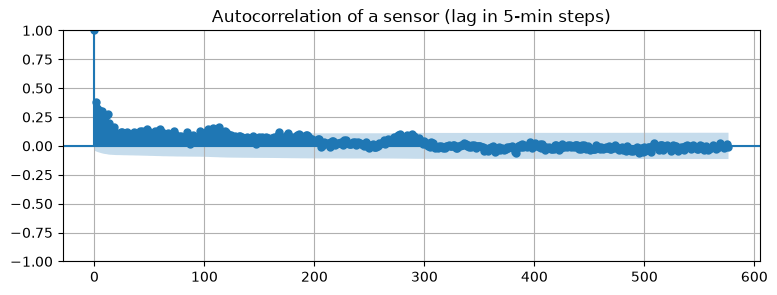

In [9]:
from statsmodels.graphics.tsaplots import plot_acf
fig, ax = plt.subplots(figsize=(9, 3))
plot_acf(s1, lags=288 * 2, ax=ax); ax.set_title("Autocorrelation of a sensor (lag in 5-min steps)"); plt.show()

## 9. Sensor correlations
How the 16 probes move together. As the paper notes, fluid-temperature sensors correlate strongly; return-air is more independent.

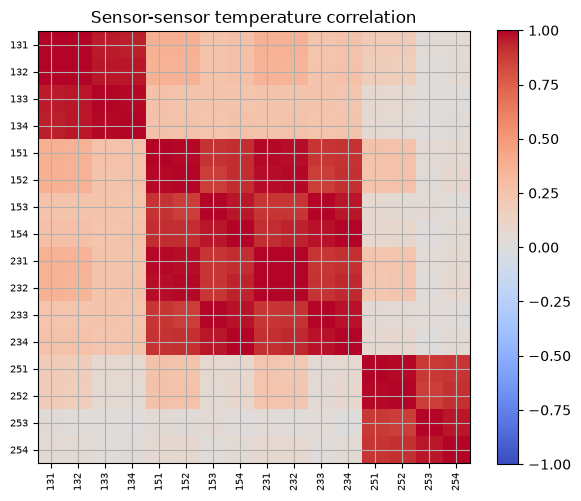

In [10]:
corr = sensors.corr()
plt.figure(figsize=(6, 5)); im = plt.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1); plt.colorbar(im)
labels = [int(c) for c in corr.columns]
plt.xticks(range(len(labels)), labels, rotation=90, fontsize=7); plt.yticks(range(len(labels)), labels, fontsize=7)
plt.title("Sensor-sensor temperature correlation"); plt.tight_layout(); plt.show()

## 10. Network traffic
Messages per hour. Sensors publish every 5 minutes, so traffic is periodic; attacks perturb it.

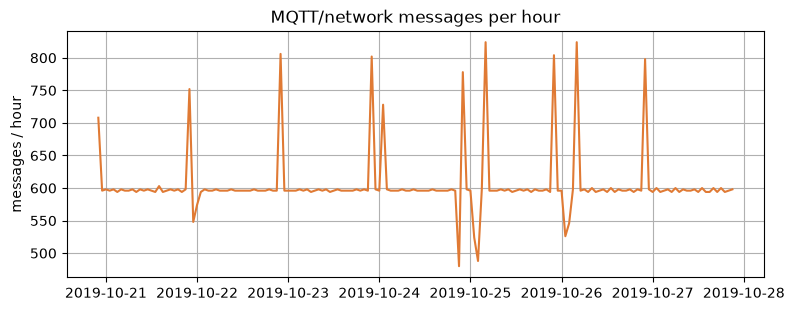

busiest hour: 2019-10-25 04:00:00 with 824 messages


In [11]:
rate = qe.message_rate(df, "1h")
plt.plot(rate.index, rate.values, color="#e07a34"); plt.title("MQTT/network messages per hour")
plt.ylabel("messages / hour"); plt.show()
ts, n = qe.busiest_hour(df); print("busiest hour:", ts, "with", n, "messages")

## 11. The attacks
Where and what kind. The counts reproduce the paper's schedule exactly (Wed 104, Thu 56, Fri/Sat 192).

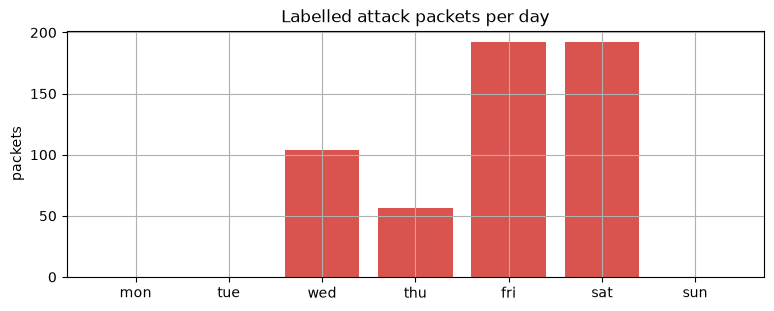

by type: {'duplication': 56, 'mixed': 384, 'modification': 104}
attacker IP: ['10.6.56.41']


In [12]:
byday = qe.attacks_by_day(df)
plt.bar(byday.keys(), byday.values(), color="#d9534f"); plt.title("Labelled attack packets per day")
plt.ylabel("packets"); plt.show()
print("by type:", qe.attack_breakdown(df))
print("attacker IP:", qe.attacker_ips(df))

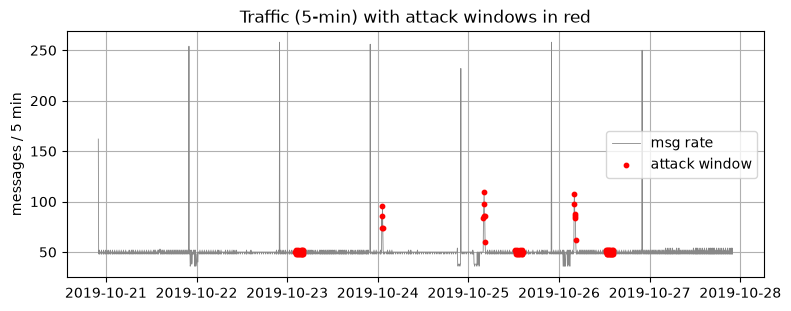

In [13]:
# attack windows highlighted on the traffic rate
wl = features.window_labels(df, "5min")
flow = features.flow_features(df, "5min").reindex(wl.index).fillna(0.0)
atk = wl[wl.label == 1]
plt.plot(flow.index, flow["msg_rate"], lw=0.6, color="#888", label="msg rate")
plt.scatter(atk.index, flow["msg_rate"].reindex(atk.index), color="red", s=10, label="attack window", zorder=3)
plt.legend(); plt.title("Traffic (5-min) with attack windows in red"); plt.ylabel("messages / 5 min"); plt.show()

## 12. The two detector channels
The attacks split across two views — which is the whole idea behind the fusion experiment:
- **Value channel** (temperature residual) catches **modification** (a bad reading breaks the pattern).
- **Flow channel** (traffic behaviour) catches **duplication / interception** (rate & timing shift).

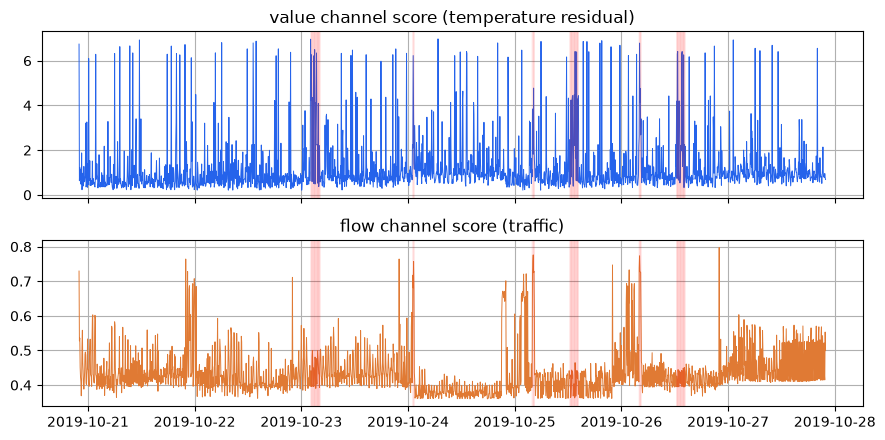

In [14]:
vs = channels.value_score(sensors.reindex(wl.index))
fs = channels.flow_score(flow)
fig, ax = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True)
ax[0].plot(vs.index, vs.values, color="#2563eb", lw=0.7); ax[0].set_title("value channel score (temperature residual)")
ax[1].plot(fs.index, fs.values, color="#e07a34", lw=0.7); ax[1].set_title("flow channel score (traffic)")
for a in ax:
    for t in atk.index: a.axvline(t, color="red", alpha=0.04)
plt.tight_layout(); plt.show()

## 13. Detection results — two channels + fusion (real labels)
Single channels vs early/late fusion vs a supervised combiner, with window-level and point-adjusted
(event-level) metrics and 95% bootstrap CIs. See `report/MODELS.md` for the full reading.

In [15]:
res = experiment.run_experiment(df)
res[["config", "AP", "AP_lo", "AP_hi", "f1", "precision", "recall", "f1_pa", "recall_pa"]].round(3)

,config,AP,AP_lo,AP_hi,f1,precision,recall,f1_pa,recall_pa
0,flow_only,0.136,0.077,0.222,0.226,0.412,0.156,0.294,0.178
1,value_only,0.183,0.136,0.245,0.379,0.331,0.444,0.804,0.889
2,early_fusion,0.147,0.108,0.206,0.289,0.202,0.511,0.732,1.000
3,late_fusion,0.171,0.123,0.246,0.306,0.214,0.533,0.789,1.000
4,supervised,0.101,0.075,0.141,0.212,0.147,0.378,0.554,1.000


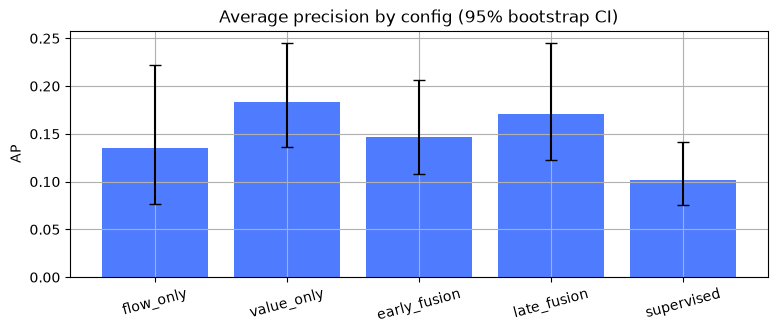

In [16]:
plt.bar(res.config, res.AP, yerr=[res.AP - res.AP_lo, res.AP_hi - res.AP], capsize=4, color="#4f7cff")
plt.title("Average precision by config (95% bootstrap CI)"); plt.ylabel("AP"); plt.xticks(rotation=15); plt.show()

**Reading.** The per-type recall (in `report/MODELS.md`) shows flow-only gets 0.00 recall on
*modification* but 1.00 on *duplication* — the channels are complementary. Fusion trades precision for
recall and reaches 1.00 point-adjusted (event-level) recall, but the AP confidence intervals overlap, so
**no config is significantly best on AP**. The *supervised* combiner does **worst** under honest
day-blocked CV — attack type is confounded with day, so a learned weighting doesn't transfer.

## 14. Ask in plain English
The interface routes a question to the exact query engine and returns a trust-labelled answer (an optional local LLM rewords it, gated by a faithfulness check).

In [17]:
bot = interface.Interface(df)
for q in ["How many attacks on Wednesday?", "Which IP is the attacker?",
          "What was the highest temperature on Friday?", "Give me a summary of Thursday"]:
    print("Q:", q, "\n  ->", bot.ask(q).text)

Q: How many attacks on Wednesday? 
  -> There were 104 labelled attack packets on Wednesday.
Q: Which IP is the attacker? 
  -> The attack traffic comes from 10.6.56.41.
Q: What was the highest temperature on Friday? 
  -> The highest reported temperature on Friday was 29.28 °C.
Q: Give me a summary of Thursday 
  -> Thursday: 14,538 messages, 56 labelled attack packets, temperatures 9.0–29.3 °C.


## 15. Conclusions
- The DAD capture is complete and its labels reproduce the paper's schedule exactly — **real** ground
  truth, unlike v1's synthetic anomalies.
- Temperatures show clean **daily seasonality** (STL + ACF), and cooling sensors are strongly correlated.
- The two detector channels are genuinely **complementary** (each blind to the other's attack type).
- **Honest headline:** fusion trades precision for recall and catches every attack *episode*
  (point-adjusted recall 1.00), but no configuration is significantly best on AP, and a *supervised*
  combiner generalises **worse** under day-blocked CV — a caution about scarce, episode-clustered labels.
- Every number here comes from deterministic code; the LLM only explains, gated by a faithfulness check.
